# Performance Optimization with NumPy and Pandas

pandas works in memory. A dataset that is too large or code that is too slow can usually be fixed in a few steps: read less data, use smaller types, vectorise, and process in chunks. This lesson measures each step on 3 million taxi trips.

**After this lesson you can:**

1. Measure memory use and time correctly.
2. Reduce memory with column selection, downcasting, `category` and Arrow strings.
3. Read only what you need from Parquet (columns and row filters).
4. Process data larger than memory in chunks.
5. Choose the next tool when pandas is not enough.

**Data:** NYC yellow taxi trips, January 2024 (3 million rows, 19 columns).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

import gc

import pyarrow.parquet as pq

PATH = datasets.taxi("2024-01")

def mb(df: pd.DataFrame) -> float:
    return df.memory_usage(deep=True).sum() / 1e6

t = time.perf_counter()
full = pd.read_parquet(PATH)
print(f"read all columns: {time.perf_counter() - t:.2f} s, {mb(full):.0f} MB in memory, {full.shape}")

read all columns: 0.57 s, 418 MB in memory, (2964624, 19)


## 1. Where Does the Memory Go?

`memory_usage(deep=True)` counts the real size of each column, including the text values.

In [2]:
usage = (full.memory_usage(deep=True, index=False) / 1e6).sort_values(ascending=False)
print(full.dtypes.astype(str).to_frame("dtype").join(usage.rename("MB").round(1)).sort_values("MB", ascending=False).head(8))

                                dtype    MB
store_and_fwd_flag                str  26.6
tpep_dropoff_datetime  datetime64[us]  23.7
tpep_pickup_datetime   datetime64[us]  23.7
improvement_surcharge         float64  23.7
passenger_count               float64  23.7
trip_distance                 float64  23.7
RatecodeID                    float64  23.7
fare_amount                   float64  23.7


## 2. Smaller Types

| Step | Example |
| :--- | :--- |
| downcast integers | `PULocationID` (1–265) fits in `int16`; `payment_type` in `int8` |
| downcast floats | `float32` is enough for amounts in dollars and cents shown with 2 decimals |
| low-cardinality text | `category` stores each label once plus small integer codes |
| text | `string[pyarrow]` (the pandas 3 default `str`) is much smaller than Python objects |

In [3]:
steps = {"original": mb(full)}
opt = full.copy()
for col in ["VendorID", "PULocationID", "DOLocationID", "payment_type"]:
    opt[col] = pd.to_numeric(opt[col], downcast="integer")
steps["downcast integers"] = mb(opt)
for col in opt.select_dtypes("float64").columns:
    opt[col] = opt[col].astype("float32")
steps["float64 -> float32"] = mb(opt)
opt["store_and_fwd_flag"] = opt["store_and_fwd_flag"].astype("category")
opt["RatecodeID"] = opt["RatecodeID"].astype("category")
steps["category for codes"] = mb(opt)
print({k: f"{v:.0f} MB" for k, v in steps.items()})
print("largest rounding error from float32 in total_amount:",
      float((full["total_amount"] - opt["total_amount"].astype("float64")).abs().max().round(6)))

{'original': '418 MB', 'downcast integers': '376 MB', 'float64 -> float32': '234 MB', 'category for codes': '202 MB'}
largest rounding error from float32 in total_amount: 4.9e-05


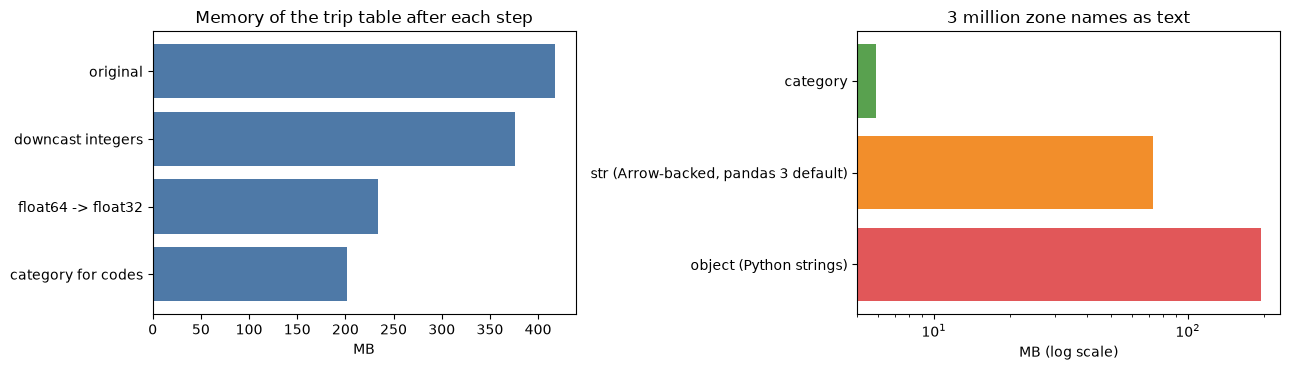

{'object (Python strings)': '193.7 MB', 'str (Arrow-backed, pandas 3 default)': '72.7 MB', 'category': '5.9 MB'}


In [4]:
zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))
names = full["PULocationID"].map(zones.set_index("LocationID")["Zone"])
text_mb = {"object (Python strings)": names.astype(object).memory_usage(deep=True) / 1e6,
           "str (Arrow-backed, pandas 3 default)": names.memory_usage(deep=True) / 1e6,
           "category": names.astype("category").memory_usage(deep=True) / 1e6}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.barh(list(steps)[::-1], list(steps.values())[::-1], color="#4E79A7")
ax1.set(title="Memory of the trip table after each step", xlabel="MB")
ax2.barh(list(text_mb), list(text_mb.values()), color=["#E15759", "#F28E2B", "#59A14F"])
ax2.set(xscale="log", title="3 million zone names as text", xlabel="MB (log scale)")
plt.tight_layout()
plt.show()
print({k: f"{v:.1f} MB" for k, v in text_mb.items()})

## 3. Read Less: Columns and Row Filters

Parquet is columnar, so reading 4 columns reads only those columns from disk. `filters=` uses the min/max statistics of each row group to skip blocks and drop rows while reading.

In [5]:
del full, opt
gc.collect()
reads = {}
for label, kwargs in [("all columns", {}),
                      ("4 columns", {"columns": ["tpep_pickup_datetime", "PULocationID", "fare_amount", "tip_amount"]}),
                      ("4 columns + filter", {"columns": ["tpep_pickup_datetime", "PULocationID", "fare_amount", "tip_amount"],
                                              "filters": [("PULocationID", "in", [132, 138])]})]:
    t = time.perf_counter()
    df = pd.read_parquet(PATH, **kwargs)
    reads[label] = (time.perf_counter() - t, mb(df), len(df))
    del df
for k, (s, m, n) in reads.items():
    print(f"{k:<20} {s:5.2f} s  {m:6.0f} MB  {n:>9,} rows")

all columns           0.34 s     418 MB  2,964,624 rows
4 columns             0.12 s      83 MB  2,964,624 rows
4 columns + filter    0.21 s       7 MB    234,773 rows


## 4. Chunked Processing

When the data does not fit in memory, process it in **chunks** and combine partial results. The aggregation must be **decomposable**: sums and counts can be added across chunks; a median cannot (it needs all values, or an approximation).

In [6]:
pf = pq.ParquetFile(PATH)
print("row groups in the file:", pf.metadata.num_row_groups)
sums, counts = pd.Series(dtype="float64"), pd.Series(dtype="float64")
t = time.perf_counter()
for batch in pf.iter_batches(batch_size=500_000, columns=["PULocationID", "fare_amount"]):
    chunk = batch.to_pandas()
    g = chunk.groupby("PULocationID")["fare_amount"]
    sums = sums.add(g.sum(), fill_value=0)
    counts = counts.add(g.count(), fill_value=0)
chunked_mean = (sums / counts).sort_index()
elapsed = time.perf_counter() - t

direct = pd.read_parquet(PATH, columns=["PULocationID", "fare_amount"]).groupby("PULocationID")["fare_amount"].mean()
print(f"chunked mean fare per zone in {elapsed:.2f} s; identical to the in-memory result: {np.allclose(chunked_mean, direct)}")

row groups in the file: 3


chunked mean fare per zone in 0.16 s; identical to the in-memory result: True


## 5. Faster Computation

| Technique | Typical gain |
| :--- | :--- |
| vectorised expressions instead of `apply`/loops (Lesson 09) | 10–100× |
| built-in `groupby` aggregations instead of lambdas (Lesson 10) | 10× and more |
| `category` keys in `groupby` | faster grouping on text keys |
| sorted index for repeated range lookups (Lesson 07) | $O(\log n)$ instead of $O(n)$ |
| Polars or DuckDB for large scans (Lessons 16–18) | multi-core, lazy, out-of-core |

In [7]:
df = pd.read_parquet(PATH, columns=["PULocationID", "fare_amount"])
df["zone"] = df["PULocationID"].map(zones.set_index("LocationID")["Zone"])
df["zone_cat"] = df["zone"].astype("category")
timings = {}
for key in ["zone", "zone_cat", "PULocationID"]:
    t = time.perf_counter()
    for _ in range(3):
        df.groupby(key, observed=True)["fare_amount"].mean()
    timings[f"groupby on {key}"] = (time.perf_counter() - t) / 3 * 1000
print({k: f"{v:.0f} ms" for k, v in timings.items()})

{'groupby on zone': '99 ms', 'groupby on zone_cat': '49 ms', 'groupby on PULocationID': '40 ms'}


## 6. When pandas Is Not Enough

| Situation | Next tool |
| :--- | :--- |
| data fits in memory, code is slow | vectorise; then Polars (multi-threaded) |
| data is larger than memory on one machine | Polars lazy/streaming, DuckDB (Lessons 17–18) |
| data is spread over a cluster | Spark, Ray Data (M13) |
| numeric loops that cannot be vectorised | Numba, Cython, or a compiled extension (M39) |

*Insight: Optimise in this order: read less (columns, filters), store smaller (dtypes, categories), compute smarter (vectorise, built-in aggregations), then change the tool. Measure before and after each step.*

## Real-World Use Case or Analogy

Optimising a DataFrame is like **packing for a flight with a weight limit**: first leave behind what you do not need (columns), then fold clothes tightly (smaller dtypes), and only if it still does not fit, ship a second suitcase (chunks) or book a bigger plane (Polars, DuckDB, Spark).

Teams often cut cloud costs and job times by large factors with exactly these steps, before they consider a distributed system.